In [1]:
import numpy as np

def create_blend_mask(h, w, overlap_px_h, overlap_px_w):
    """Creates a 2D linear ramp mask for smooth blending."""
    mask_h = np.ones(h, dtype=np.float32)
    mask_w = np.ones(w, dtype=np.float32)
    
    # Linear ramp for height edges
    mask_h[:overlap_px_h] = np.linspace(0, 1, overlap_px_h)
    mask_h[-overlap_px_h:] = np.linspace(1, 0, overlap_px_h)
    
    # Linear ramp for width edges
    mask_w[:overlap_px_w] = np.linspace(0, 1, overlap_px_w)
    mask_w[-overlap_px_w:] = np.linspace(1, 0, overlap_px_w)
    
    return mask_h[:, None] * mask_w[None, :]

def stitch_blend_serpentine(img, grid_shape=(3, 3), overlap=0.1):
    """
    Stitches tiles using a blend projection (feathered averaging).
    """
    print(img.shape)
    try:
        N, C, H, W = img.shape
    except ValueError:
        N, H, W = img.shape
        C = 1
    rows, cols = grid_shape
    
    overlap_h = int(H * overlap)
    overlap_w = int(W * overlap)
    step_h = H - overlap_h
    step_w = W - overlap_w
    
    full_h = H + (rows - 1) * step_h
    full_w = W + (cols - 1) * step_w
    
    stitched = np.zeros((C, full_h, full_w), dtype=np.float32)
    weights = np.zeros((full_h, full_w), dtype=np.float32)
    
    # Create the blending mask
    blend_mask = create_blend_mask(H, W, overlap_h, overlap_w)

    for r in range(rows):
        for c in range(cols):
            i = r * cols + c
            
            # Serpentine pattern mapping
            if r % 2 == 0:
                tile_idx = i
            else:
                row_start = r * cols
                row_end = (r + 1) * cols - 1
                tile_idx = row_end - (i - row_start)
            
            y_start = r * step_h
            x_start = c * step_w
            
            # Apply weighted tile to canvas
            stitched[:, y_start:y_start+H, x_start:x_start+W] += img[tile_idx] * blend_mask
            weights[y_start:y_start+H, x_start:x_start+W] += blend_mask
            
    # Normalize by total weights to finalize the blend
    stitched /= np.maximum(weights, 1e-6)
    
    return stitched


In [ ]:
import os
import xml.etree.ElementTree as ET
from aicspylibczi import CziFile
from bioio import BioImage
import numpy as np
from ome_types.model import Color, Pixels_DimensionOrder, PixelType, TiffData
from skimage.exposure import rescale_intensity
from tifffile import imwrite
from tqdm import tqdm


def norm(img, low=1, high=99):
  return rescale_intensity(
      img,
      in_range=(np.percentile(img, low), np.percentile(img, high)),
      out_range=(0, 1),
  )


def build_stitched_ome(img, scene_idx, stitched, name, n_tiles, grid_shape):
  """Builds the OME-XML of a stitched scene from the CZI metadata.

  Starts from the OME metadata bioio extracted from the CZI (instrument,
  objective, detector, channel names / wavelengths, pixel size, acquisition
  date...) and updates the pixel layout to describe the stitched mosaic. The
  full, untouched CZI XML is attached as a structured annotation so nothing is
  lost.

  Args:
    img: BioImage of the CZI file.
    scene_idx: Index of the scene being exported.
    stitched: Stitched array, shape (C, Y, X) or (Y, X).
    name: Name given to the OME image.
    n_tiles: Number of tiles that were stitched.
    grid_shape: (rows, cols) of the tile grid.

  Returns:
    The OME-XML, UTF-8 encoded.
  """
  ome = img.ome_metadata.model_copy(deep=True)

  # Keep only the image of the current scene.
  image = ome.images[scene_idx]
  ome.images = [image]
  image.id = "Image:0"
  image.name = name
  image.description = (
      f"Stitched from {n_tiles} tiles ({grid_shape[0]}x{grid_shape[1]} grid, "
      "serpentine, linear blending)"
  )

  # Update the pixel layout: the stitched mosaic replaces the tile stack.
  size_c = stitched.shape[0] if stitched.ndim == 3 else 1
  pixels = image.pixels
  pixels.id = "Pixels:0"
  pixels.size_x = stitched.shape[-1]
  pixels.size_y = stitched.shape[-2]
  pixels.size_c = size_c
  pixels.size_z = 1
  pixels.size_t = 1
  pixels.dimension_order = Pixels_DimensionOrder.XYZCT
  pixels.type = PixelType(
      {"float32": "float", "float64": "double"}.get(
          stitched.dtype.name, stitched.dtype.name
      )
  )
  if stitched.dtype.kind == "f":
    pixels.significant_bits = None  # Only meaningful for integer pixels
  pixels.planes = []

  # Channel display colors: bioio leaves them white, but ZEN stores them in the
  # CZI display settings as #AARRGGBB (e.g. DAPI blue, EGFP green).
  zen_colors = {
      ch.get("Name"): ch.findtext("Color")
      for ch in img.metadata.findall(".//DisplaySetting/Channels/Channel")
  }
  for channel in pixels.channels:
    channel.samples_per_pixel = 1
    argb = zen_colors.get(channel.name)
    if argb:
      channel.color = Color(f"#{argb[-6:]}")
  pixels.tiff_data_blocks = [TiffData(ifd=0, plane_count=size_c)]

  # Original CZI XML, kept as is. ome-types cannot serialize arbitrary
  # elements, so it is spliced into the XML tree afterwards.
  ome_ns = "http://www.openmicroscopy.org/Schemas/OME/2016-06"
  ET.register_namespace("", ome_ns)
  root = ET.fromstring(ome.to_xml())
  annotations = root.find(f"{{{ome_ns}}}StructuredAnnotations")
  if annotations is None:
    annotations = ET.SubElement(root, f"{{{ome_ns}}}StructuredAnnotations")
  czi_annotation = ET.SubElement(
      annotations,
      f"{{{ome_ns}}}XMLAnnotation",
      ID="Annotation:CZI_metadata",
      Namespace="zeiss.com/CZI-metadata",
  )
  ET.SubElement(czi_annotation, f"{{{ome_ns}}}Description").text = (
      "Original Zeiss CZI metadata"
  )
  ET.SubElement(czi_annotation, f"{{{ome_ns}}}Value").append(img.metadata)
  # Returned as UTF-8 bytes: Bio-Formats (Fiji) cannot parse numeric character
  # references such as "&#181;" for the micro sign in "µm" and would silently
  # fall back to a plain TIFF (channels read as Z or T).
  return ET.tostring(root, encoding="utf-8")
#mother_folder = r"/mnt/data/work/These/Data/2026_Billes_Cerebellum"
#for date_folder in os.listdir(mother_folder):
output_folder = r"/mnt/data/work/These/Data/2026_Billes_Cerebellum/20261027"
files = os.listdir(output_folder)

for file in files:
  if file.endswith(".czi") and not file.startswith("."):
    img_path = os.path.join(output_folder, file)
    print(f"\nProcessing file: {file}")

    czi = CziFile(img_path)
    num_scenes = len(czi.scenes) if hasattr(czi, "scenes") else 1
    print(f"Found {num_scenes} scene(s) in {file}")

    img = BioImage(
        img_path,e
        reconstruct_mosaic=False,
        include_subblock_metadata=False,
        use_aicspylibczi=True,
    )

    scenes = img.scenes if hasattr(img, "scenes") and img.scenes else [None]

    for scene_idx, scene in enumerate(scenes):
      if scene is not None:
        img.set_scene(scene)
      try:
        print(f"--- Scene {scene_idx + 1}/{len(scenes)} ---")
        raw_shape = img.data.shape
        print("Raw tile data shape:", raw_shape)

        if len(raw_shape) == 6:
          M, T, C, Z, Y, X = raw_shape
          data = img.data[:, 0, :, 0, :, :]  # Shape: (M, C, Y, X)
        else:
          data = img.data.squeeze()
          if data.ndim == 2:
            data = np.expand_dims(data, axis=1)

        N = data.shape[0]
        num_channels = data.shape[1] if data.ndim >= 4 else 1

        print(f"Number of tiles (N): {N}, Channels: {num_channels}")

        if N == 6:
          grid_shape = (3, 2)
        elif N == 4:
          grid_shape = (2, 2)
        elif N == 9:
          grid_shape = (3, 3)
        elif N == 12:
          grid_shape = (4, 3)
        elif N == 20:
          grid_shape = (5, 4)
        elif N == 36:
          grid_shape = (9, 4)
        else:
          grid_shape = (4, 2)

        stitched_channels = []
        for c in range(num_channels):
          if data.ndim >= 4:
            channel_tiles = data[:, c, :, :]
          else:
            channel_tiles = data

          stitched_c = stitch_blend_serpentine(
              channel_tiles, grid_shape=grid_shape
          )
          stitched_channels.append(stitched_c)

        # Recombine channels: stack along axis=0 to get (C, Y, X)
        if len(stitched_channels) > 1:
          stitched_img = np.stack(stitched_channels, axis=0)
        else:
          stitched_img = stitched_channels[0]
        stitched_img = np.squeeze(stitched_img)
        output_filename = file.replace(
            ".czi", f"_scene_{scene_idx+1}_stitched.ome.tiff"
        )
        output_path = os.path.join(output_folder, output_filename)

        # Write an OME-TIFF carrying the CZI metadata
        ome_xml = build_stitched_ome(
            img,
            scene_idx,
            stitched_img,
            name=output_filename.replace(".ome.tiff", ""),
            n_tiles=N,
            grid_shape=grid_shape,
        )
        pixel_size_um = img.physical_pixel_sizes.X  # None if not in the CZI
        resolution = (
            dict(
                resolution=(1 / pixel_size_um, 1 / pixel_size_um),
                resolutionunit="MICROMETER",
            )
            if pixel_size_um
            else {}
        )
        imwrite(
            output_path,
            stitched_img,
            bigtiff=True,
            photometric="minisblack",
            description=ome_xml,
            ome=False,  # we provide the OME-XML, tifffile must not build its own
            metadata=None,
            **resolution,
        )
        print(f"Saved: {output_path}")
      except Exception as e:
        print(f"Error processing scene {scene_idx + 1}: {e}")


Processing file: Experiment_3084.czi
Found 1 scene(s) in Experiment_3084.czi
--- Scene 1/4 ---
Raw tile data shape: (9, 1, 3, 1, 1040, 1392)
Number of tiles (N): 9, Channels: 3
(9, 1040, 1392)
(9, 1040, 1392)
(9, 1040, 1392)
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261027/Experiment_3084_scene_1_stitched.ome.tiff
--- Scene 2/4 ---
Raw tile data shape: (6, 1, 3, 1, 1040, 1392)
Number of tiles (N): 6, Channels: 3
(6, 1040, 1392)
(6, 1040, 1392)
(6, 1040, 1392)
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261027/Experiment_3084_scene_2_stitched.ome.tiff
--- Scene 3/4 ---
Raw tile data shape: (6, 1, 3, 1, 1040, 1392)
Number of tiles (N): 6, Channels: 3
(6, 1040, 1392)
(6, 1040, 1392)
(6, 1040, 1392)
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261027/Experiment_3084_scene_3_stitched.ome.tiff
--- Scene 4/4 ---
Raw tile data shape: (6, 1, 3, 1, 1040, 1392)
Number of tiles (N): 6, Channels: 3
(6, 1040, 1392)
(6, 1040, 1392)
(6, 1040, 1392)
Saved: /m

In [4]:
3+3

6

Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261013/merged/tranches_scene_1_merged.ome.tiff
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261013/merged/tranches_scene_2_merged.ome.tiff
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261013/merged/tranches_scene_3_merged.ome.tiff
Saved: /mnt/data/work/These/Data/2026_Billes_Cerebellum/20261013/merged/tranches_scene_4_merged.ome.tiff


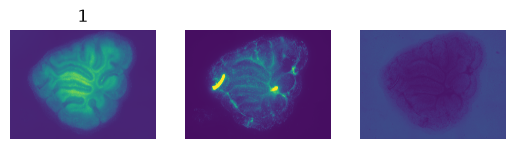

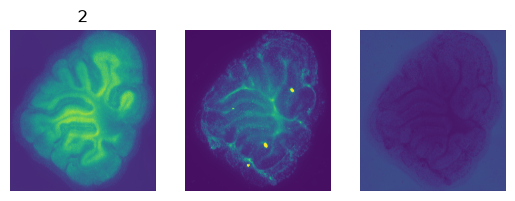

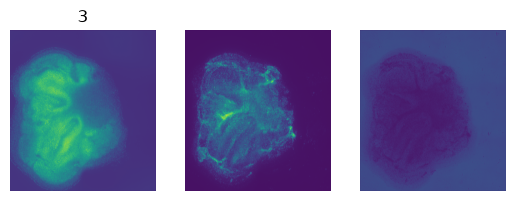

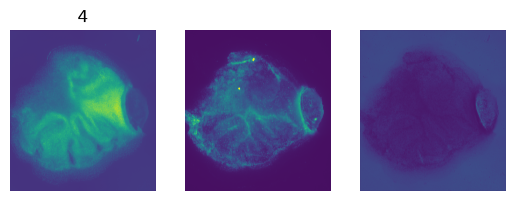

In [ ]:
import copy
import matplotlib.pyplot as plt
from skimage.io import imread
import numpy as np
import os
import tifffile
import xml.etree.ElementTree as ET

OME_NS = "http://www.openmicroscopy.org/Schemas/OME/2016-06"
ET.register_namespace("", OME_NS)
ET.register_namespace("xsi", "http://www.w3.org/2001/XMLSchema-instance")


def q(tag):
    return f"{{{OME_NS}}}{tag}"


def read_ome(path):
    """Returns the OME-XML root stored in an OME-TIFF."""
    with tifffile.TiffFile(path) as tif:
        return ET.fromstring(tif.pages[0].description.encode("utf-8"))


def merge_ome(sources, channel_order, shape, name, description):
    """Builds the OME-XML of an image whose channels come from several OME-TIFFs.

    The first source is the base (instrument, pixel size, acquisition date...).
    Channels are copied (name, color, wavelengths...) from the source they come
    from, and the raw CZI XML of every source is kept as an annotation.

    Args:
      sources: {label: OME root} of the stitched files.
      channel_order: [(label, channel index in that file), ...], output order.
      shape: (C, Y, X) of the merged array.
      name: Name given to the OME image.
      description: Description given to the OME image.

    Returns:
      The OME-XML, UTF-8 encoded.
    """
    base = sources[channel_order[0][0]]
    image = base.find(q("Image"))
    pixels = image.find(q("Pixels"))

    # Channels, in the order of the merged array
    channels = []
    for label, c in channel_order:
        src_pixels = sources[label].find(q("Image")).find(q("Pixels"))
        channels.append(copy.deepcopy(src_pixels.findall(q("Channel"))[c]))
    for old in pixels.findall(q("Channel")):
        pixels.remove(old)
    for c, channel in enumerate(channels):
        channel.set("ID", f"Channel:0:{c}")
        pixels.insert(c, channel)

    pixels.set("SizeC", str(shape[0]))
    pixels.set("SizeY", str(shape[1]))
    pixels.set("SizeX", str(shape[2]))
    pixels.set("SizeZ", "1")
    pixels.set("SizeT", "1")
    for tiff_data in pixels.findall(q("TiffData")):
        tiff_data.set("IFD", "0")
        tiff_data.set("PlaneCount", str(shape[0]))

    image.set("Name", name)
    desc = image.find(q("Description"))
    if desc is None:
        desc = ET.Element(q("Description"))
        # Schema order: AcquisitionDate, ExperimenterRef, Description, ...
        position = sum(
            child.tag in (q("AcquisitionDate"), q("ExperimenterRef"))
            for child in image
        )
        image.insert(position, desc)
    desc.text = description

    # Instrument parts (detectors, objectives, light sources) of the other
    # sources that the base does not have; elements with the same ID are the same.
    instrument = base.find(q("Instrument"))
    known_ids = {el.get("ID") for el in instrument}
    for label, root in sources.items():
        other = root.find(q("Instrument"))
        if root is base or other is None:
            continue
        for el in other:
            if el.get("ID") not in known_ids:
                instrument.append(copy.deepcopy(el))
                known_ids.add(el.get("ID"))

    # Raw CZI metadata of each source, one annotation per file
    annotations = base.find(q("StructuredAnnotations"))
    for label, root in sources.items():
        for ann in root.iter(q("XMLAnnotation")):
            if ann.get("ID") == "Annotation:CZI_metadata":
                ann = copy.deepcopy(ann)
                ann.set("ID", f"Annotation:CZI_metadata_{label}")
                ann.find(q("Description")).text = f"Original Zeiss CZI metadata ({label})"
                annotations.append(ann)
    for ann in list(annotations):
        if ann.get("ID") == "Annotation:CZI_metadata":
            annotations.remove(ann)  # the base's own, re-added above

    return ET.tostring(base, encoding="utf-8")


folder = r"/mnt/data/work/These/Data/2026_Billes_Cerebellum/20261027"
output_folder = os.path.join(folder, "merged")
os.makedirs(output_folder, exist_ok=True)
files = os.listdir(folder)
for i in range(1,len(files)):
    list_images = list()
    list_files = list()
    for file in files:
        if file.endswith('.tiff') and file.__contains__('billes') and file.__contains__('scene_'+str(i)):
            list_images.append(imread(os.path.join(folder,file)))
            list_files.append(file)
    if len(list_images)>1:
        # Sort by file name so that the order does not depend on the listing
        list_files, list_images = map(list, zip(*sorted(zip(list_files, list_images), key=lambda p: p[0])))
        # Channels of the merged image: (index in list_files, channel in that file).
        # This single list drives both the pixels and the metadata.
        channel_order = [(0, 0), (1, 1), (0, 1)]
        img_stacked = np.stack([list_images[f][c] for f, c in channel_order])
        fig,ax = plt.subplots(1,3)
        ax[0].imshow(img_stacked[0])
        ax[1].imshow(img_stacked[1])
        ax[2].imshow(img_stacked[2])
        for a in ax:
            a.axis('off')
        ax[0].set_title(str(i))

        # Save as OME-TIFF, with the metadata of the stitched files
        labels = [f.replace("_stitched.ome.tiff", "") for f in list_files]
        sources = {
            label: read_ome(os.path.join(folder, f))
            for label, f in zip(labels, list_files)
        }
        output_name = f"tranches_scene_{i}_merged"
        ome_xml = merge_ome(
            sources,
            [(labels[f], c) for f, c in channel_order],
            img_stacked.shape,
            name=output_name,
            description="Merge of " + " and ".join(list_files),
        )
        pixel_size_um = sources[labels[0]].find(q("Image")).find(q("Pixels")).get("PhysicalSizeX")
        resolution = (
            dict(
                resolution=(1 / float(pixel_size_um), 1 / float(pixel_size_um)),
                resolutionunit="MICROMETER",
            )
            if pixel_size_um
            else {}
        )
        output_path = os.path.join(output_folder, output_name + ".ome.tiff")
        tifffile.imwrite(
            output_path,
            img_stacked,
            bigtiff=True,
            photometric="minisblack",
            description=ome_xml,
            ome=False,  # we provide the OME-XML, tifffile must not build its own
            metadata=None,
            **resolution,
        )
        print(f"Saved: {output_path}")

In [28]:
list_files

['Experiment-3059_billes_bright_focus_hoechst_scene_1_stitched.ome.tiff',
 'Experiment-3059_billes_bright_focus_hoechst_scene_2_stitched.ome.tiff',
 'Experiment-3059_billes_bright_focus_hoechst_scene_3_stitched.ome.tiff',
 'Experiment-3059_billes_bright_focus_hoechst_scene_4_stitched.ome.tiff',
 'Experiment-3060_billes_hoechst_focus_billes_scene_1_stitched.ome.tiff',
 'Experiment-3060_billes_hoechst_focus_billes_scene_2_stitched.ome.tiff',
 'Experiment-3060_billes_hoechst_focus_billes_scene_3_stitched.ome.tiff',
 'Experiment-3060_billes_hoechst_focus_billes_scene_4_stitched.ome.tiff']